# hERG cardiotoxicity classifier — results

Can hERG blockade (pIC50 ≥ 5, i.e. IC50 ≤ 10 µM) be predicted from structure?

This notebook reads the outputs of `scripts/01_fetch_chembl.py`, `02_prepare.py` and `03_model.py`; it does not retrain anything. Re-run the scripts to regenerate them.

In [1]:
import json, pandas as pd
from IPython.display import Image, display
summary = json.load(open('../data/processed/summary.json'))
metrics = json.load(open('../results/metrics.json'))

## 1. Data: ChEMBL → clean, labelled compounds

In [2]:
print(summary['source'])
pd.DataFrame(summary['filters'])

{'target': 'CHEMBL240', 'pref_name': 'Voltage-gated inwardly rectifying potassium channel KCNH2', 'organism': 'Homo sapiens', 'chembl_version': 'ChEMBL_37', 'n_activities': 19130, 'downloaded': '2026-10-13'}


,step,kept,dropped
0,exact '=' relation,12021,7109
1,"units nM, value > 0",12010,11
2,has SMILES,12008,2
3,wild-type channel (no assay_variant_mutation),11985,23
4,no ChEMBL validity flag,11694,291
5,2 < pIC50 < 12,11694,0


In [3]:
pd.Series({k: summary[k] for k in ['n_measurements', 'n_unique_compounds', 'n_at_exactly_10uM']})

n_measurements        11694
n_unique_compounds     9586
n_at_exactly_10uM       185
dtype: int64

In [4]:
summary['replicates']

{'n_compounds': 1172, 'median_sd': 0.0, 'p75_sd': 0.214, 'p90_sd': 0.636}

In [5]:
{k: v for k, v in summary['label'].items() if k != 'rationale'}

{'threshold_pIC50': 5.0,
 'band': 0.3,
 'n_ambiguous': 3208,
 'n_labelled': 6378,
 'n_blocker': 4646,
 'n_non_blocker': 1732,
 'n_scaffolds': 3470}

In [6]:
print(summary['label']['rationale'])

pIC50 5 (10 uM) is the common early-discovery hERG flag. The +/-0.3 band exceeds the p75 replicate SD, so a compound inside it could land on either side on re-measurement.


## 2. Splits

The scaffold split keeps every Bemis–Murcko scaffold on one side, so the test set contains chemotypes the model has never seen. It is the headline number; the random split is shown to make the optimism of random splitting visible.

In [7]:
pd.DataFrame(metrics['splits']).T

,train,test,test_positive_fraction,scaffolds_shared_train_test
scaffold,5103.0,1275.0,0.7506,0.0
random,5103.0,1275.0,0.7341,468.0


## 3. Performance

5-fold CV inside the training set (scaffold-grouped folds for the scaffold split), then a single fit evaluated on the held-out test set.

In [8]:
rows = []
for key, r in metrics['results'].items():
    split, model = key.split('/')
    rows.append({'split': split, 'model': model,
                 **{f'cv_{m}': f"{r['cv_mean'][m]:.3f} ± {r['cv_sd'][m]:.3f}" for m in ['ROC_AUC', 'PR_AUC', 'MCC']},
                 **{f'test_{m}': round(v, 3) for m, v in r['test'].items()}})
pd.DataFrame(rows)

,split,model,cv_ROC_AUC,cv_PR_AUC,cv_MCC,test_ROC_AUC,test_PR_AUC,test_MCC,test_Brier
0,scaffold,RandomForest,0.869 ± 0.022,0.943 ± 0.011,0.489 ± 0.026,0.889,0.955,0.539,0.117
1,scaffold,LightGBM,0.857 ± 0.021,0.935 ± 0.013,0.507 ± 0.028,0.883,0.955,0.541,0.115
2,random,RandomForest,0.908 ± 0.011,0.962 ± 0.006,0.566 ± 0.041,0.923,0.969,0.641,0.098
3,random,LightGBM,0.896 ± 0.012,0.955 ± 0.007,0.601 ± 0.030,0.917,0.965,0.643,0.096


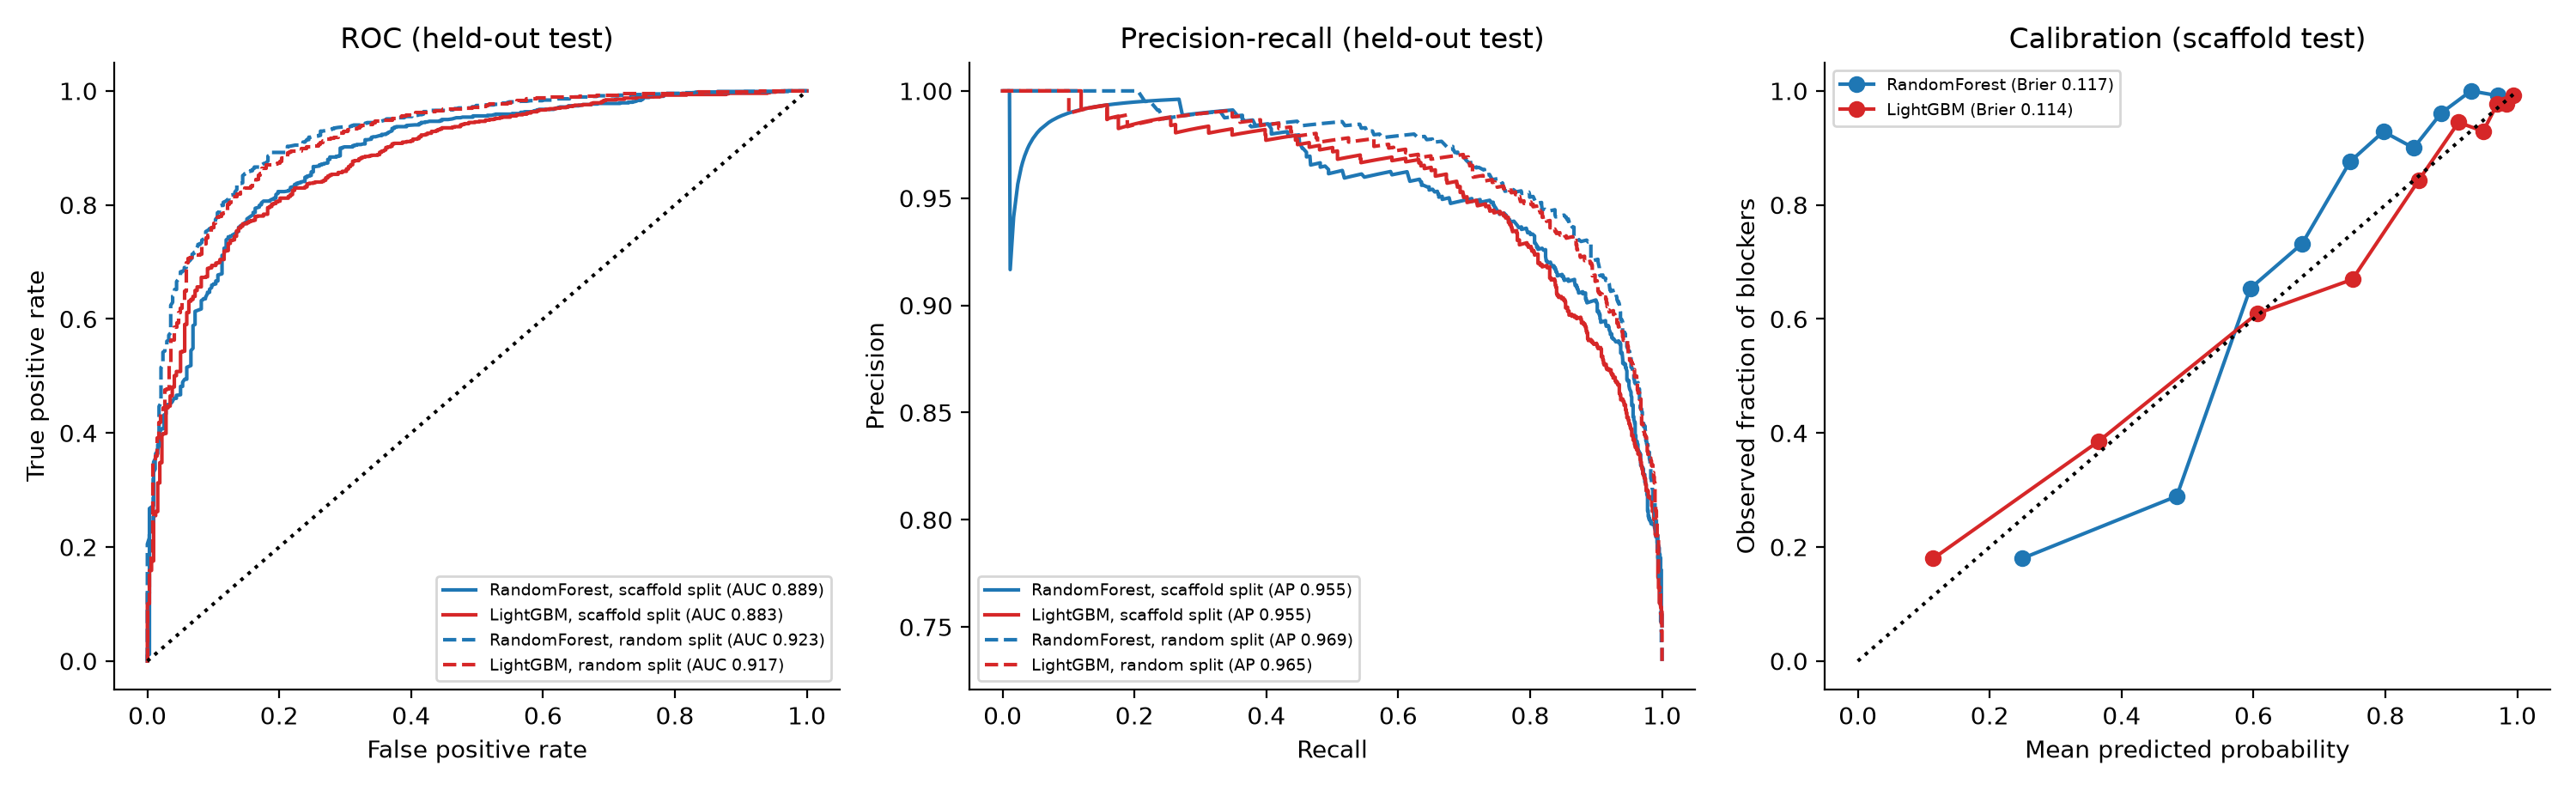

In [9]:
display(Image('../figures/fig1_roc_pr_calibration.png', width=1000))

## 4. Applicability domain

Scaffold-test compounds binned by Tanimoto similarity to their nearest training compound (LightGBM).

In [10]:
print('median nearest-neighbour Tanimoto:', metrics['test_nn_tanimoto_median'])
pd.DataFrame(metrics['applicability_domain'])

median nearest-neighbour Tanimoto: 0.6769


,nn_tanimoto,n,ROC_AUC
0,0.0-0.4,182,0.7779
1,0.4-0.5,80,0.8124
2,0.5-0.6,157,0.8137
3,0.6-0.7,312,0.9164
4,0.7-1.0,544,0.9201


## 5. Sensitivity to the excluded band

LightGBM, scaffold split, with the uncertainty band around pIC50 5 set to 0 (no exclusion), 0.3 (used) and 0.5.

In [11]:
pd.read_csv('../results/band_sensitivity.csv')

,band,n,positive_fraction,ROC_AUC,PR_AUC,MCC,Brier
0,0.0,9586,0.6779,0.8004,0.8943,0.4112,0.1649
1,0.3,6378,0.7284,0.8828,0.9549,0.5411,0.1145
2,0.5,4468,0.8109,0.9065,0.9731,0.4710,0.1108


## 6. What drives predictions (SHAP, LightGBM, scaffold test)

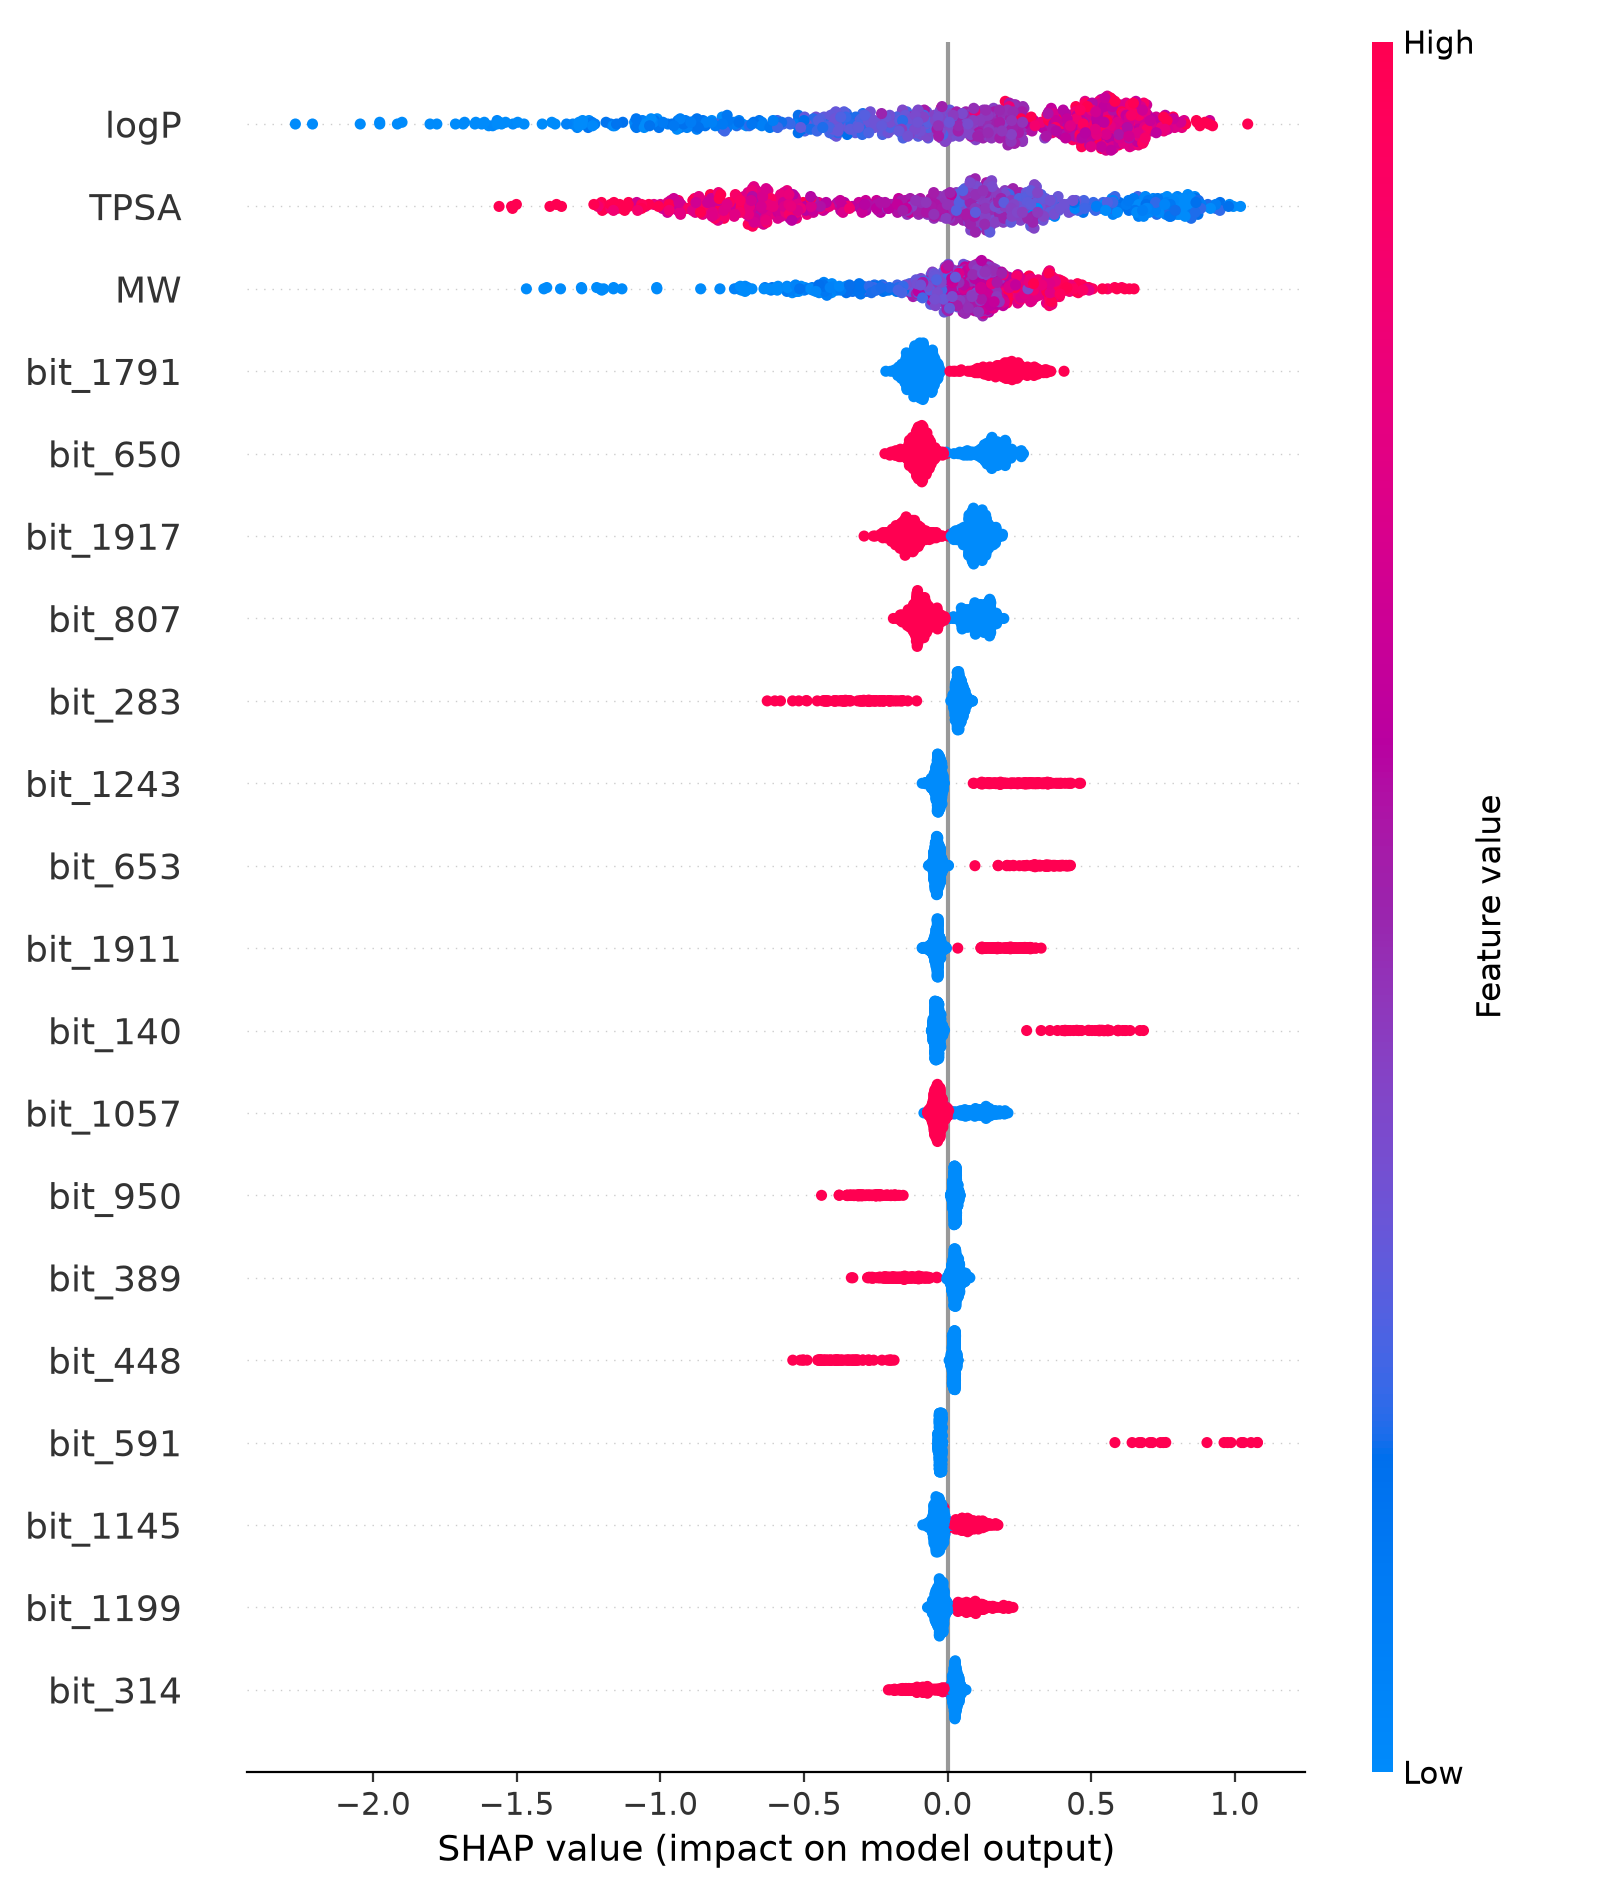

,feature,mean_abs_shap
0,logP,0.484002
1,TPSA,0.477706
2,MW,0.223553
3,bit_1791,0.131200
4,bit_650,0.118845
5,bit_1917,0.117264
6,bit_807,0.100688
7,bit_283,0.069876
8,bit_1243,0.067426
9,bit_653,0.061823


In [12]:
display(Image('../figures/fig2_shap_summary.png', width=700))
pd.read_csv('../results/shap_top20.csv').head(10)